# Threshold curve in the $(p, p_{\mathrm{bell},z})$ plane — `biased_bell_v2` & `biased_bell_v3`

Headline figure: every fitted threshold is a 2D point $(p^*, p_{\mathrm{bell},z}^*)$
on the noise plane. Both noise models are drawn as separate curves.

- **bias scan**: direction $\beta = p_{\mathrm{bell},z}/p$, threshold lands at
  $(p^*, \beta \cdot p^*)$.
- **fixed-$p_{\mathrm{bell},z}$ scan**: $p_{\mathrm{bell},z}$ held constant,
  threshold lands at $(p^*, p_{\mathrm{bell},z}^{\mathrm{fixed}})$.

Reads the per-direction fits saved by `threshold_comparison_bell.ipynb`
(`out/collection/threshold_bell_fits.csv`).

In [17]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [18]:
fits_path = Path('../out/collection/threshold_bell_fits.csv')
if not fits_path.exists():
    raise FileNotFoundError(
        f'No fits at {fits_path}. Run threshold_comparison_bell.ipynb first.'
    )

fits_df = pd.read_csv(fits_path)

# Backwards-compat: older fits CSVs lacked the noise_model column.
if 'noise_model' not in fits_df.columns:
    fits_df['noise_model'] = 'biased_bell_v2'

print('fits per noise_model:')
print(fits_df.groupby('noise_model').size())
fits_df

fits per noise_model:
noise_model
biased_bell_v2    12
biased_bell_v3    11
dtype: int64


,noise_model,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,biased_bell_v2,bias=0,bias,0.0,NaN,0.002418,2.159251e-05,0.910499,0.044097,0.002512,15
1,biased_bell_v2,bias=1,bias,1.0,NaN,0.002047,1.233021e-05,0.971927,0.035426,0.002154,14
2,biased_bell_v2,bias=2,bias,2.0,NaN,0.001701,2.051408e-05,0.756509,0.026000,0.001585,13
3,biased_bell_v2,bias=3,bias,3.0,NaN,0.001486,9.182376e-06,0.954573,0.026916,0.001585,14
4,biased_bell_v2,bias=5,bias,5.0,NaN,0.001196,1.259919e-05,0.815859,0.025822,0.001166,13
5,biased_bell_v2,bias=10,bias,10.0,NaN,0.000795,4.923095e-06,0.880964,0.021115,0.000858,14
6,biased_bell_v2,bias=20,bias,20.0,NaN,0.000492,6.146875e-06,0.713299,0.025259,0.000464,13
7,biased_bell_v2,bias=30,bias,30.0,NaN,0.000348,2.581181e-06,0.791440,0.017868,0.000341,13
8,biased_bell_v2,bias=50,bias,50.0,NaN,0.000220,1.991365e-06,0.884524,0.030904,0.000251,12
9,biased_bell_v2,bias=100,bias,100.0,NaN,0.000116,8.823396e-07,0.963759,0.036348,0.000136,9


In [19]:
NOISE_MODEL_COLORS = {
    'biased_bell_v2': '#e15759',  # red-ish
    'biased_bell_v3': '#4e79a7',  # blue-ish
}
NOISE_MODELS_PRESENT = sorted(
    fits_df['noise_model'].unique(),
    key=lambda m: list(NOISE_MODEL_COLORS).index(m) if m in NOISE_MODEL_COLORS else 99,
)

bias_by_model = {
    m: fits_df[(fits_df['noise_model'] == m) & (fits_df['direction_kind'] == 'bias')]
        .sort_values('bias').reset_index(drop=True)
    for m in NOISE_MODELS_PRESENT
}
pbz_by_model = {
    m: fits_df[(fits_df['noise_model'] == m) & (fits_df['direction_kind'] == 'pbz')]
        .sort_values('p_bell_z_fixed').reset_index(drop=True)
    for m in NOISE_MODELS_PRESENT
}
for m in NOISE_MODELS_PRESENT:
    print(f'{m}: {len(bias_by_model[m])} bias points, '
          f'{len(pbz_by_model[m])} fixed-pbz points')

biased_bell_v2: 10 bias points, 2 fixed-pbz points
biased_bell_v3: 9 bias points, 2 fixed-pbz points


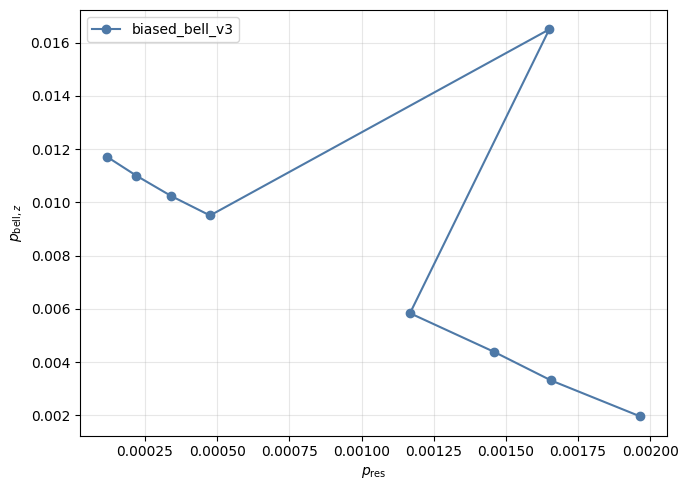

In [26]:
# Each fitted threshold -> point (p_th, beta * p_th) on the (p, p_bell_z) plane.
# One curve per noise model.
fig, ax = plt.subplots(figsize=(7, 5))


# for model in NOISE_MODELS_PRESENT:
for model in ['biased_bell_v3']:
    bdf = bias_by_model[model]
    if bdf.empty:
        continue
    p = bdf['p_th'].to_numpy(dtype=float)
    pbz = bdf['bias'].to_numpy(dtype=float) * p
    ax.plot(p, pbz, 'o-', color=NOISE_MODEL_COLORS.get(model, 'k'),
            label=model)

ax.set_xlabel(r'$p_\text{res}$')
ax.set_ylabel(r'$p_{\mathrm{bell},z}$')
# ax.set_title(r'Threshold points $(p^*, \beta p^*)$')
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.savefig('../out/figures/threshold_bell_curves.pdf', bbox_inches='tight')
plt.show()

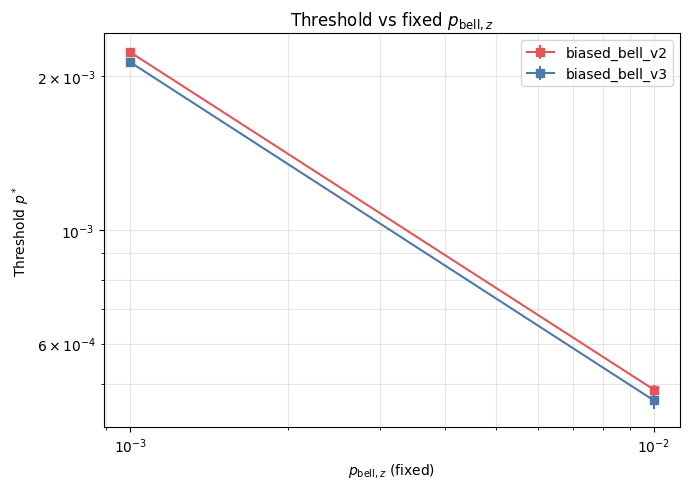

In [21]:
# p_th vs fixed p_bell_z (independent scan, easier to interpret
# experimentally because p_bell_z is set by hardware). One curve per noise model.
fig, ax = plt.subplots(figsize=(7, 5))
plotted = False
for model in NOISE_MODELS_PRESENT:
    pdf = pbz_by_model[model]
    if pdf.empty:
        continue
    plotted = True
    ax.errorbar(
        pdf['p_bell_z_fixed'], pdf['p_th'], yerr=pdf['p_th_err'],
        fmt='s-', color=NOISE_MODEL_COLORS.get(model, 'k'),
        label=f'{model}',
    )
if plotted:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(r'$p_{\mathrm{bell},z}$ (fixed)')
    ax.set_ylabel(r'Threshold $p^*$')
    ax.set_title(r'Threshold vs fixed $p_{\mathrm{bell},z}$')
    ax.grid(True, alpha=0.3, which='both')
    ax.legend()
    fig.tight_layout()
    plt.show()
else:
    print('No fixed-pbz fits to plot.')

In [ ]:
# Combined view: both scans on one (p_bell_z, p_th) plane, one set of curves
# per noise model.
# - bias scan: each point is (p_th * beta, p_th).
# - fixed-pbz scan: each point is (p_bell_z_fixed, p_th).
fig, ax = plt.subplots(figsize=(7, 5))

for model in NOISE_MODELS_PRESENT:
    color = NOISE_MODEL_COLORS.get(model, 'k')
    bdf = bias_by_model[model]
    if not bdf.empty:
        bx = bdf['bias'] * bdf['p_th']
        ax.errorbar(
            bx, bdf['p_th'], yerr=bdf['p_th_err'],
            fmt='o-', color=color, label=f'{model} bias scan',
        )
    pdf = pbz_by_model[model]
    if not pdf.empty:
        ax.errorbar(
            pdf['p_bell_z_fixed'], pdf['p_th'], yerr=pdf['p_th_err'],
            fmt='s--', color=color, label=f'{model} fixed-pbz',
        )

ax.plot(
    [1e-6, 1.0], [1e-6, 1.0],
    color='gray', linestyle=':', alpha=0.5, label=r'$p^* = p_{\mathrm{bell},z}$',
)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$p_{\mathrm{bell},z}$ at threshold')
ax.set_ylabel(r'Threshold $p^*$')
ax.set_title(r'Threshold trajectories on the $(p_{\mathrm{bell},z}, p)$ plane')
ax.grid(True, alpha=0.3, which='both')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()